# Phase 2 — Unsupervised Learning: K-Means (Member A)
**Project:** CCO Flight Booking & Passenger Advisory Dashboard  
**Course:** SWE485 — Group 5  
**Scope:** Member A: data preparation, K-Means, selection of k, Silhouette, Davies–Bouldin, WCSS, and reusable clustering output.

**Rationale.** K-Means is an interpretable, efficient centroid-based baseline for segmenting 50,000 airline booking records into groups with similar booking characteristics. It allows the executive dashboard to summarize passenger profiles. Because Euclidean distances depend on scale, we reuse Phase 1 preprocessing and standardize its two frequency-encoded columns. K-Means does **not** use the booking completion target; any completion-rate comparisons are strictly post-hoc descriptions, not evidence of causation.

**Limitations.** Euclidean K-Means assumes roughly compact groups and is sensitive to feature weighting, outliers, and frequency encoding, which can collapse distinct routes or countries into the same numeric value. The redundant `total_extra_services` feature also weights ancillary preferences more heavily. Results are exploratory and should be compared with Member B's alternative clustering method.

## 1. Load the processed data and remove labels

**Colab portability:** The loader checks local project paths first, then retrieves the same datasets from the project’s public GitHub repository if the files are not present. Internet access is needed only for the fallback.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
# Prefer local project files; use the public GitHub dataset when running in a fresh Colab session.
paths = [Path('../Dataset/preprocessed_data.csv'), Path('Dataset/preprocessed_data.csv'), Path('preprocessed_data.csv')]
DATA_PATH = next((p for p in paths if p.exists()), None)
if DATA_PATH is not None:
    print('Loading processed data from:', DATA_PATH)
    data = pd.read_csv(DATA_PATH)
else:
    processed_url = ('https://raw.githubusercontent.com/Ghaida-Alyousef/'
                     'SW485-Project-Group5/main/Dataset/preprocessed_data.csv')
    print('Local processed data not found; loading from project GitHub...')
    try:
        data = pd.read_csv(processed_url)
    except Exception as exc:
        raise RuntimeError('Could not load preprocessed_data.csv from local paths or GitHub. '
                           'Check the internet connection and repository path.') from exc
assert len(data) == 50000 and {'booking_complete', 'data_split'}.issubset(data.columns)
X = data.drop(columns=['booking_complete', 'data_split']).copy()
assert X.select_dtypes(exclude='number').empty and not X.isna().any().any()
print('Data:', data.shape, '| Clustering features:', X.shape)
print('Excluded: booking_complete and data_split')

Local processed data not found; loading from project GitHub...
Data: (50000, 25) | Clustering features: (50000, 23)
Excluded: booking_complete and data_split


## 2. Feature scaling
Six numerical features were already standardized during Phase 1. Binary and one-hot indicators are left in their 0/1 representation. The frequency-encoded `route` and `booking_origin` have very small ranges, so we standardize them to avoid almost ignoring them in Euclidean distance. This is an explicit modeling choice; it increases the influence of these two columns and should be tested in sensitivity analysis. The target and split indicator never enter the scaling or clustering matrix.

In [ ]:
X_scaled = X.copy()
frequency_columns = ['route', 'booking_origin']
X_scaled[frequency_columns] = StandardScaler().fit_transform(X_scaled[frequency_columns])
X_array = X_scaled.to_numpy(dtype=np.float32)
print('Clustering matrix:', X_array.shape)

Clustering matrix: (50000, 23)


## 3. Select k: Elbow, Silhouette and Davies–Bouldin
To make the k-search practical on 50,000 records, use a deterministic random subset of 12,000 rows for candidate fitting and a fixed 1,800-row sample for Silhouette. WCSS values from this search are comparable with each other **only because the same 12,000-row sample is used**. Silhouette is maximized; Davies–Bouldin is minimized. The elbow plot is used as additional context rather than an automatic criterion.

,k,wcss,silhouette,davies_bouldin
0,2,102644.5547,0.1343,2.5459
1,3,93619.8594,0.1325,2.2353
2,4,84309.4922,0.1550,1.9185
3,5,78096.9375,0.1444,1.8493
4,6,72971.4766,0.1473,1.6886
5,7,68463.3359,0.1553,1.6252
6,8,64778.8086,0.1460,1.6861


Selected k: 7


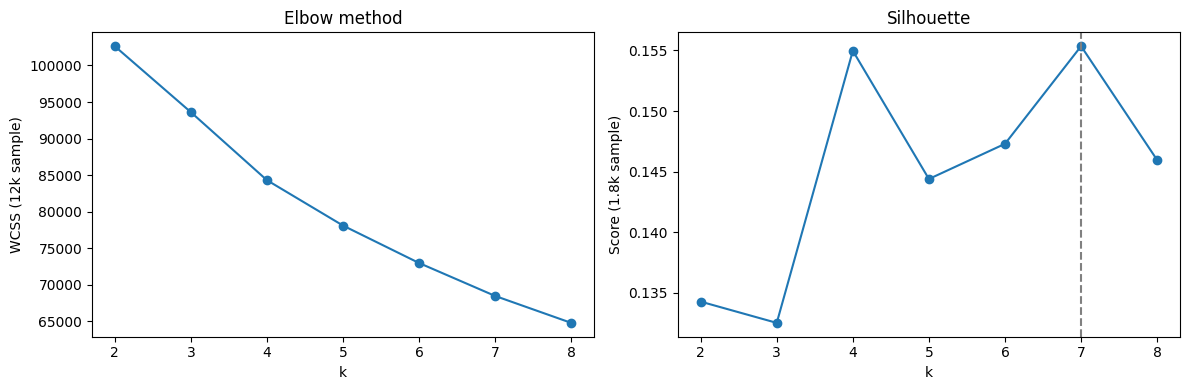

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
search_indices = rng.choice(len(X_array), size=12000, replace=False)
search_X = X_array[search_indices]
results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE, algorithm='lloyd')
    labels = km.fit_predict(search_X)
    results.append({'k': k, 'wcss': km.inertia_,
                    'silhouette': silhouette_score(search_X, labels, sample_size=1800, random_state=RANDOM_STATE),
                    'davies_bouldin': davies_bouldin_score(search_X, labels)})
metrics = pd.DataFrame(results)
best_k = int(metrics.sort_values(['silhouette', 'davies_bouldin'], ascending=[False, True]).iloc[0]['k'])
display(metrics.round(4))
print('Selected k:', best_k)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(metrics.k, metrics.wcss, 'o-'); ax[0].set(title='Elbow method', xlabel='k', ylabel='WCSS (12k sample)')
ax[1].plot(metrics.k, metrics.silhouette, 'o-'); ax[1].axvline(best_k, linestyle='--', color='gray'); ax[1].set(title='Silhouette', xlabel='k', ylabel='Score (1.8k sample)')
plt.tight_layout(); plt.show()

## 4. Fit the final model on all 50,000 bookings
Use the selected k, with 20 initializations for stability. Final Silhouette is estimated from 2,500 sampled rows. Davies–Bouldin is evaluated on the **same** 12,000 search rows, using labels from the full-data model; this is a sample-based estimate. WCSS comes from all 50,000 records and must not be compared numerically with the 12,000-row k-search WCSS.

In [ ]:
final_model = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE, algorithm='lloyd')
cluster_labels = final_model.fit_predict(X_array)
final_silhouette = silhouette_score(X_array, cluster_labels, sample_size=2500, random_state=RANDOM_STATE)
final_db = davies_bouldin_score(X_array[search_indices], cluster_labels[search_indices])
print(f'k={best_k}; Silhouette (sampled)={final_silhouette:.4f}; Davies-Bouldin (sampled)={final_db:.4f}; Full-data WCSS={final_model.inertia_:.2f}')
print(pd.Series(cluster_labels).value_counts().sort_index())

k=7; Silhouette (sampled)=0.1540; Davies-Bouldin (sampled)=1.6248; Full-data WCSS=285413.94
0     4772
1    13272
2    16075
3     2792
4     2624
5      888
6     9577
Name: count, dtype: int64


## 5. Export reusable clustering output

In [ ]:
output = data.copy()
output.insert(0, 'row_id', np.arange(len(data)))
output['cluster'] = cluster_labels
assert len(output) == len(data) == len(cluster_labels)
assert output['row_id'].is_unique and output['cluster'].nunique() == best_k
assert output['cluster'].notna().all()
output.to_csv('clustered_data.csv', index=False)
metrics.to_csv('kmeans_k_selection.csv', index=False)
print('Saved clustered_data.csv:', output.shape)
display(output[['row_id','booking_complete','data_split','cluster']].head())

Saved clustered_data.csv: (50000, 27)


,row_id,booking_complete,data_split,cluster
0,0,0,test,0
1,1,0,train,2
2,2,0,train,0
3,3,0,train,2
4,4,0,train,6


## 6. Cluster profiles (post-hoc only)
For interpretable units, use the original raw data if available. The `booking_complete` column is used **only after fitting** to describe how observed completion rates vary across clusters. This does not make clustering supervised.

In [14]:

from pathlib import Path
from io import BytesIO
import requests

# 1. Load original raw data
raw_paths = [
    Path('../Dataset/customer_booking.csv'),
    Path('Dataset/customer_booking.csv'),
    Path('customer_booking.csv')
]

raw_path = next((p for p in raw_paths if p.exists()), None)

if raw_path is not None:
    print('Loading raw data from:', raw_path)
    raw = pd.read_csv(raw_path, encoding='latin1')
else:
    raw_url = (
        'https://raw.githubusercontent.com/Ghaida-Alyousef/'
        'SW485-Project-Group5/main/Dataset/customer_booking.csv'
    )

    print('Local raw data not found; loading from project GitHub...')

    response = requests.get(raw_url, timeout=30)
    response.raise_for_status()

    raw = pd.read_csv(
        BytesIO(response.content),
        encoding='latin1'
    )

# 2. Verify raw data matches processed data
assert len(raw) == len(data), 'Raw and processed row counts differ'

assert np.array_equal(
    raw['booking_complete'].to_numpy(),
    data['booking_complete'].to_numpy()
), 'Raw/processed row order mismatch'

# 3. Attach K-Means cluster labels
raw['cluster'] = cluster_labels

# 4. Generate cluster profiles
profiles = raw.groupby('cluster').agg(
    bookings=('booking_complete', 'size'),
    completion_rate=('booking_complete', 'mean'),
    median_purchase_lead=('purchase_lead', 'median'),
    median_length_of_stay=('length_of_stay', 'median'),
    mean_flight_duration=('flight_duration', 'mean'),
    extra_baggage_rate=('wants_extra_baggage', 'mean'),
    preferred_seat_rate=('wants_preferred_seat', 'mean'),
    meal_rate=('wants_in_flight_meals', 'mean')
)

# 5. Calculate cluster percentage
profiles['share_pct'] = profiles['bookings'] / len(raw) * 100

# 6. Save results
profiles.to_csv('kmeans_cluster_profiles.csv')

print('Raw data shape:', raw.shape)
print('Saved kmeans_cluster_profiles.csv')
display(profiles.round(3))


Local raw data not found; loading from project GitHub...
Raw data shape: (50000, 15)
Saved kmeans_cluster_profiles.csv


,bookings,completion_rate,median_purchase_lead,median_length_of_stay,mean_flight_duration,extra_baggage_rate,preferred_seat_rate,meal_rate,share_pct
cluster,,,,,,,,,
0,4772,0.142,269.0,6.0,7.133,0.538,0.208,0.271,9.544
1,13272,0.054,48.0,22.0,8.464,0.729,0.345,0.546,26.544
2,16075,0.165,36.0,6.0,6.377,0.451,0.056,0.104,32.150
3,2792,0.167,97.5,6.0,6.881,0.843,0.325,0.484,5.584
4,2624,0.211,102.0,21.0,8.830,0.675,0.227,0.451,5.248
5,888,0.133,31.0,175.0,7.729,0.882,0.390,0.592,1.776
6,9577,0.238,42.0,6.0,6.864,0.943,0.682,0.843,19.154


## 7. Cluster sizes and PCA visualization

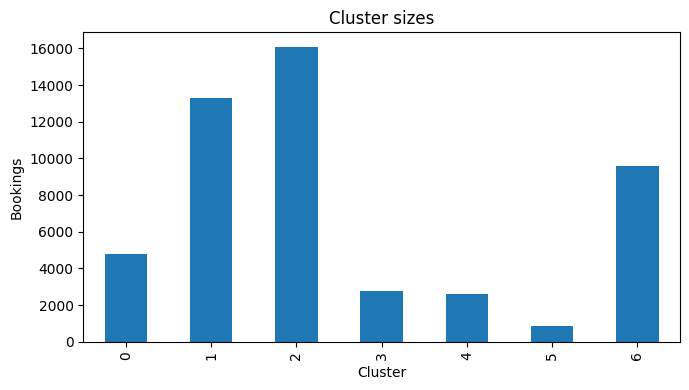

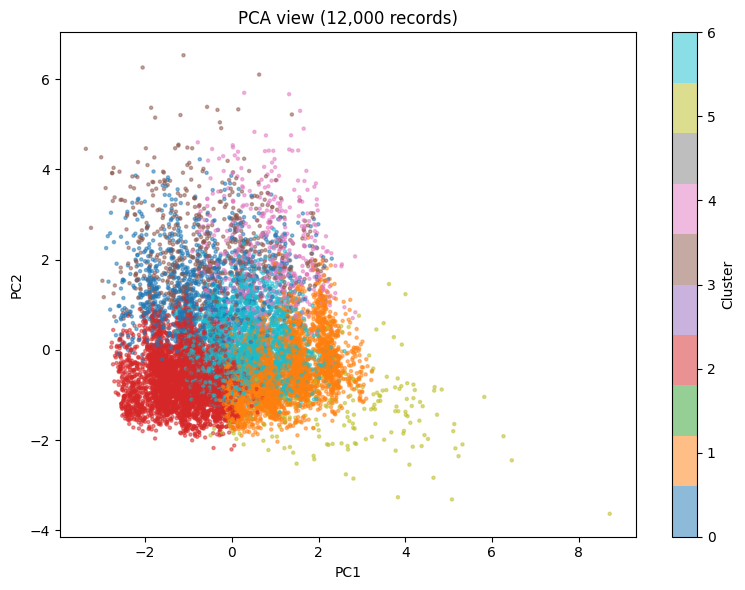

PCA explained variance: 0.30849254


In [ ]:
fig, ax = plt.subplots(figsize=(7,4))
pd.Series(cluster_labels).value_counts().sort_index().plot.bar(ax=ax)
ax.set(title='Cluster sizes',xlabel='Cluster',ylabel='Bookings');plt.tight_layout();plt.show()
pca = PCA(n_components=2, random_state=RANDOM_STATE)
projection = pca.fit_transform(X_array[search_indices])
fig, ax = plt.subplots(figsize=(8,6))
scatter = ax.scatter(projection[:,0],projection[:,1],c=cluster_labels[search_indices],s=5,alpha=.5,cmap='tab10')
fig.colorbar(scatter,ax=ax,label='Cluster');ax.set(title='PCA view (12,000 records)',xlabel='PC1',ylabel='PC2')
plt.tight_layout();plt.show()
print('PCA explained variance:', pca.explained_variance_ratio_.sum())

## 8. Interpretation, integration and challenges

**Observed results (seed 42, current saved run):** The k-search evaluated k=2–8 on the same 12,000-record subset. The highest estimated Silhouette was **0.1553 at k=7**, only **0.0003** above k=4 (0.1550); k=7 also had a lower Davies–Bouldin score (1.6252 vs 1.9185) in this search. The elbow plot has no single unmistakable bend. Therefore **k=7 is a defensible exploratory selection, not a uniquely proven optimum**. Candidate WCSS at k=7 was **68,463.34 on 12,000 rows** and must not be compared numerically with full-data WCSS.

**Final full-data K-Means:** Fitting k=7 on all **50,000** bookings yielded **Silhouette = 0.1540** (sample of 2,500), **Davies–Bouldin = 1.6248** (12,000-row subset), and **WCSS = 285,413.94** (all 50,000). Cluster sizes for IDs 0–6 were **4,772; 13,272; 16,075; 2,792; 2,624; 888; 9,577**, respectively. The relatively low Silhouette and visible overlap in PCA indicate weak separation; clusters are exploratory segments rather than sharply distinct customer types. The first two PCA components explain **30.85%** of variance, so the 2D plot cannot fully represent separation in the original 23-dimensional space.

**Business interpretation (post-hoc raw-data profiles):** Cluster 0 has long median purchase lead (**269 days**) but short median stay (**6 days**), with **14.2%** observed booking completion. Cluster 1 represents **26.54%** of records, with longer median stays (**22 days**) and **5.4%** completion. Cluster 2 is the largest (**32.15%**), has median stay **6 days** and **16.5%** completion. Cluster 3 shows high extra-baggage preference (**84.3%**) and **16.7%** completion. Cluster 4 has median stay **21 days**, mean flight duration **8.83 hours**, and **21.1%** completion. Cluster 5 is the smallest (**1.78%**), with a notably long median stay (**175 days**), potentially reflecting extreme stays or a specialized subgroup; investigate before labeling. Cluster 6 has strong ancillary preferences (extra baggage **94.3%**, preferred seat **68.2%**, meals **84.3%**) and **23.8%** completion. Completion rates are descriptive and **were not used to form clusters**; they do not establish causality.

**Integration:** Share `clustered_data.csv` with Member B and the dashboard team. Its `row_id` preserves the original row order and may be used to join Phase 1 prediction outputs **after verifying that both files use the same row ordering**. Dashboard comparisons can show segment sizes, observed completion rates, and predicted probabilities by cluster. Cluster IDs are arbitrary labels, not ranked risk scores.

**Challenges and limitations:** K-Means uses Euclidean distance, assumes reasonably compact groups, and is sensitive to outliers and feature scaling. Standardizing frequency-encoded `route` and `booking_origin` increases their weight; frequency encoding also loses category identity. One-hot features and `total_extra_services` may duplicate some preference information. The k-search covered only k=2–8 and metrics were sampled for efficiency. Before using the segments for decisions, test stability and alternative feature weights, and compare with Member B's second clustering algorithm.

**Reproducibility:** Random seed 42, K-Means with 20 initializations for final fitting. Results shown here are from the saved notebook outputs; re-running on the same input files is recommended before submission. Small differences may occur across library versions.